# Wearable stress detection: cross-dataset analysis notebook (FTS workflow 7.0.0)

This notebook runs the complete analysis from the raw datasets to the archived result tables and figures. It only orchestrates the run: every analysis step is an ordinary Python file in the accompanying `code/` folder, executed in an isolated, version-pinned environment. See `README.md` for the file-by-file description.

**Data (not redistributed here).** Source: WESAD. Target: PhysioNet *Wearable Device Dataset from Induced Stress and Structured Exercise Sessions* v1.0.1. Both must be downloaded from their original providers and extracted to the Drive paths set in Cell 1.

**How to run.** Place the `FTS_supplement` folder in Google Drive (`MyDrive/FTS_supplement`), open this notebook in a CPU Colab runtime and choose *Runtime → Run all*. After a runtime restart, run from Cell 1 again; completed stages are verified by SHA-256 and reused, never silently recomputed or overwritten.

**Integrity.** Cell 3 checks every code, test and evidence file against `SHA256SUMS.txt`, whose own hash is fixed in this notebook. Each stage records the hashes of its inputs and outputs, and execution stops on any mismatch rather than continuing with altered files.

**Scope of the analysis.** This is a retrospective, target-informed analysis of a previously inspected evaluation cohort. The automatic signal-quality thresholds are heuristic. Both the unscreened reference analysis and the quality-sensitivity analysis are produced and reported side by side.

**Outputs shown below** are from run `fts_complete_7_d27bf7a0f70a3284`, which produced the review archive with SHA-256 `d8d9f4e1ac0493d325be7752672d06ff5e3421f4e7877410589d68e874a6561f`.

## Cell 1 — Mount Drive, fix the analysis settings and create the run folder

All design settings (seeds, cross-validation, participant partitions) are fixed here and written once to `design.json`. The run folder name is derived from these settings, so a changed setting can never overwrite an existing run.

In [ ]:
from pathlib import Path
import csv, hashlib, html, json, os, platform, subprocess, sys, zipfile
from google.colab import drive
from IPython.display import display, HTML, Markdown, Image

drive.mount('/content/drive', force_remount=False)
# Dataset and output locations on Google Drive.
WESAD_DIR = Path('/content/drive/MyDrive/WESAD')
PHYS_ROOT = Path('/content/drive/MyDrive/PhysioNet_Dataset')
WORK_ROOT = Path('/content/drive/MyDrive/FTS_publication_reanalysis')
# Accept the extra folder level that unzipping the datasets commonly creates.
if not list(WESAD_DIR.glob('S*/S*.pkl')) and (WESAD_DIR/'WESAD').is_dir(): WESAD_DIR=WESAD_DIR/'WESAD'
if not (PHYS_ROOT/'STRESS').is_dir() and (PHYS_ROOT/'Wearable_Dataset/STRESS').is_dir(): PHYS_ROOT=PHYS_ROOT/'Wearable_Dataset'
if not (3,11) <= sys.version_info[:2] <= (3,13):
    raise RuntimeError('This pinned environment requires Python 3.11–3.13. Do not change package versions to conceal an error.')
CFG = dict(workflow_version="7.0.0", version="6.0.0", seed=20260824, cv_repeats=5, cv_folds=5,
    xgb_trees=200, rf_trees=500, run_ablations=True,
    shap_background_windows=90, shap_seed=318, shap_models=["fts6","fts5","all_efs","target_importance6"],
    discovery_subjects=["S01","S03","S09","S13","S14","S15","S17","f02","f03","f04","f06","f08"],
    confirmation_subjects=["S04","S05","S06","S07","S08","S10","S16","S18","f01","f05","f09","f10","f11","f12"],
    target_development_conditions=["rest","stress"], target_evaluation_conditions=["rest","stress"],
    target_status="previously inspected cohort; retrospective secondary reanalysis",
    n_bootstrap=10000, bootstrap_seed=20260908, equivalence_margin=.02,
    cpu_hz=64000000, voltage_v=3., active_current_a=.00333)

BUNDLE_KEY = '7d72f7d893d177fd'

identity=dict(bundle=BUNDLE_KEY,configuration=CFG,python=sys.version,platform=platform.platform(),
              wesad=str(WESAD_DIR),physionet=str(PHYS_ROOT))
RUN_ID='fts_complete_7_'+hashlib.sha256(json.dumps(identity,sort_keys=True).encode()).hexdigest()[:16]
RUN_ROOT=WORK_ROOT/'complete_runs'/RUN_ID
CODE_DIR=RUN_ROOT/'code'; DATA_DIR=RUN_ROOT/'data'; MODEL_DIR=RUN_ROOT/'models'
RESULTS_DIR=RUN_ROOT/'results'; ASSET_DIR=RUN_ROOT/'assets'; TEST_DIR=RUN_ROOT/'tests'; LOG_DIR=RUN_ROOT/'logs'
for p in [RUN_ROOT,CODE_DIR,DATA_DIR,MODEL_DIR,RESULTS_DIR,ASSET_DIR,TEST_DIR,LOG_DIR]:p.mkdir(parents=True,exist_ok=True)
def digest(path):
    h=hashlib.sha256()
    with Path(path).open("rb") as f:
        for b in iter(lambda:f.read(1024*1024),b""):h.update(b)
    return h.hexdigest()

def immutable_bytes(path, data):
    path=Path(path)
    if path.exists() and path.read_bytes()!=data:
        raise RuntimeError(f"Refusing to change a recorded input: {path}. Do not overwrite completed results; retain the existing run.")
    if not path.exists():path.write_bytes(data)

def immutable_json(path, value):
    immutable_bytes(path,json.dumps(value,indent=2,sort_keys=True,allow_nan=False).encode())

def write_source(name, source):
    if Path(name).name!=name:raise ValueError("Source name must be a basename")
    immutable_bytes(CODE_DIR/name,source.encode("utf-8"))
    print("Source ready:",name)

def display_csv(path, limit=80):
    with Path(path).open(newline="") as f:
        r=csv.reader(f);headers=next(r);rows=list(r)
    def tr(row,tag):return "<tr>"+"".join(f"<{tag}>"+html.escape(str(x))+f"</{tag}>" for x in row)+"</tr>"
    display(HTML("<b>"+html.escape(Path(path).name)+"</b><table>"+tr(headers,"th")+"".join(tr(row,"td") for row in rows[:limit])+"</table>"))
    if len(rows)>limit:print(f"Showing {limit}/{len(rows)} rows; the complete CSV is saved.")

def execute(command, log_name, env=None):
    # Stream complete errors; no subprocess exceptions that conceal pip output.
    with (LOG_DIR/log_name).open("a",encoding="utf-8") as log:
        proc=subprocess.Popen([str(x) for x in command],stdout=subprocess.PIPE,stderr=subprocess.STDOUT,
            text=True,bufsize=1,env=env)
        for line in proc.stdout:print(line,end="",flush=True);log.write(line);log.flush()
        rc=proc.wait()
    if rc:raise RuntimeError(f"Command failed with exit {rc}. Read the printed output and {LOG_DIR/log_name}; do not bypass the gate.")


immutable_json(RUN_ROOT/'design.json',CFG)
immutable_json(RUN_ROOT/'paths.json',dict(wesad=str(WESAD_DIR),physionet=str(PHYS_ROOT)))
immutable_json(RUN_ROOT/'workflow_identity.json',identity)
print('Automatic run/resume folder:',RUN_ROOT)
print('After any restart, run this notebook from Cell 1. No run-number or name entry is used.')

Mounted at /content/drive
Automatic run/resume folder: /content/drive/MyDrive/FTS_publication_reanalysis/complete_runs/fts_complete_7_d27bf7a0f70a3284
After any restart, run this notebook from Cell 1. No run-number or name entry is used.


## Cell 2 — Create the isolated, version-pinned environment

The analysis runs in its own virtual environment with exact package versions, so Colab's preinstalled packages cannot affect the results. The resolved versions are saved to `requirements_frozen.txt` in the run folder.

In [ ]:
# Identical to requirements.txt in the package (checked in Cell 3).
REQUIREMENTS = '''numpy==2.2.6
scipy==1.15.3
pandas==2.2.3
scikit-learn==1.6.1
xgboost-cpu==3.0.2
shap==0.48.0
numba==0.61.2
llvmlite==0.44.0
matplotlib==3.10.3
neurokit2==0.2.12
cvxopt==1.3.2
joblib==1.5.1
'''
immutable_bytes(RUN_ROOT/"requirements.txt",REQUIREMENTS.encode())
env_key=hashlib.sha256((REQUIREMENTS+sys.version).encode()).hexdigest()[:16]
ENV_DIR=Path("/content")/("fts_complete_env_"+env_key)
PY=ENV_DIR/"bin"/"python"
if not PY.exists():
    execute([sys.executable,"-m","venv","--without-pip",ENV_DIR],"environment.log")
# Official pip --python mode manages a venv even when it has no pip installed.
PIP=[sys.executable,"-m","pip","--python",str(PY)]
execute(PIP+["install","--only-binary=:all:","--disable-pip-version-check","-r",RUN_ROOT/"requirements.txt"],"environment.log")
execute(PIP+["check"],"environment.log")
freeze=subprocess.run(PIP+["freeze"],capture_output=True,text=True,check=True).stdout
immutable_bytes(RUN_ROOT/"requirements_frozen.txt",freeze.encode())
runtime=subprocess.run([str(PY),"-c","import sys,platform,json;print(json.dumps({'python':sys.version,'platform':platform.platform()}))"],capture_output=True,text=True,check=True)
immutable_json(RUN_ROOT/"runtime.json",json.loads(runtime.stdout))
ENV=os.environ.copy()
ENV.update(FTS_DATA_DIR=str(DATA_DIR),FTS_WESAD_DIR=str(WESAD_DIR),FTS_PHYS_ROOT=str(PHYS_ROOT),
    FTS_PREP_MODE="extract",MPLBACKEND="Agg",PYTHONUNBUFFERED="1",OMP_NUM_THREADS="1",OPENBLAS_NUM_THREADS="1")
print("Isolated environment checks passed. Colab kernel packages were not changed.")

ENV['PYTHONPATH']=str(CODE_DIR)
ENV['FTS_TRUST_WESAD_PICKLES']='1'  # User-specified official WESAD data only.

## Cell 3 — Install the analysis code, tests and protocol evidence

Copies `code/`, `tests/` and `assets/` from the package into the run folder, after checking every file against `SHA256SUMS.txt`. The files are plain text and can be read directly in the package.

In [ ]:
PACKAGE_MANIFEST_SHA256 = '0b5f37503a8650451dcd6992cf51c6e851e232b2cd2152028f3869cc62bb9e5d'
PACKAGE_LOCATIONS = [Path('/content/drive/MyDrive/FTS_supplement'), Path('/content/FTS_supplement')]

PACKAGE_DIR = next((p for p in PACKAGE_LOCATIONS if (p/'SHA256SUMS.txt').is_file()), None)
if PACKAGE_DIR is None:
    raise FileNotFoundError('Supplementary package not found. Place the FTS_supplement folder at one of: '
                            + ', '.join(map(str, PACKAGE_LOCATIONS)))
if digest(PACKAGE_DIR/'SHA256SUMS.txt') != PACKAGE_MANIFEST_SHA256:
    raise RuntimeError('SHA256SUMS.txt does not match this notebook. Use the package released with it.')

installed = {'code': 0, 'tests': 0, 'assets': 0}
for line in (PACKAGE_DIR/'SHA256SUMS.txt').read_text().splitlines():
    expected, relative = line.split('  ', 1)
    source = PACKAGE_DIR/relative
    if '..' in Path(relative).parts or not source.is_file():
        raise FileNotFoundError('Package file missing or invalid: ' + relative)
    if digest(source) != expected:
        raise RuntimeError('Package file differs from its recorded SHA-256: ' + relative)
    folder = Path(relative).parts[0]
    if folder in installed:
        destination = RUN_ROOT/relative
        destination.parent.mkdir(parents=True, exist_ok=True)
        immutable_bytes(destination, source.read_bytes())
        installed[folder] += 1
if (PACKAGE_DIR/'requirements.txt').read_text() != REQUIREMENTS:
    raise RuntimeError('requirements.txt differs from the versions pinned in Cell 2.')
TOOLS_DIR = PACKAGE_DIR/'tools'
print('Package verified:', PACKAGE_DIR)
print('Installed into the run folder:', installed)

## Cell 4 — Define the stage runner

`stage()` runs one analysis script and records the SHA-256 of all its inputs (including the code and environment) and outputs. On a re-run, a completed stage is reused only if every recorded hash still matches; otherwise execution stops.

In [ ]:
def fingerprint(inputs):
    files = list(map(Path, inputs)) + list(CODE_DIR.glob('*.py')) + [
        RUN_ROOT/'design.json', RUN_ROOT/'requirements_frozen.txt', RUN_ROOT/'runtime.json']
    return {str(p): digest(p) for p in sorted(set(files))}


def stage(name, command, inputs, products):
    current = fingerprint(inputs)
    marker = RUN_ROOT/('stage_' + name + '.json')
    if marker.exists():
        # Completed earlier: verify inputs and outputs instead of recomputing.
        previous = json.loads(marker.read_text())
        if previous['inputs'] != current:
            raise RuntimeError(name + ': recorded inputs changed; no stale reuse allowed.')
        for p, h in previous['outputs'].items():
            if not Path(p).is_file() or digest(p) != h:
                raise RuntimeError(name + ': missing or changed completed output: ' + p)
        if name == 'extract':
            for p, info in json.loads((DATA_DIR/'raw_input_hashes.json').read_text()).items():
                if not Path(p).is_file() or digest(p) != info['sha256']:
                    raise RuntimeError('Raw input changed: ' + p)
        print(name + ': verified completed stage reused')
        return
    execute(command, name + '.log', ENV)
    outputs = []
    for product in products:
        p = Path(product)
        if p.is_dir():
            outputs.extend(q for q in p.rglob('*') if q.is_file() and '__pycache__' not in q.parts)
        else:
            outputs.append(p)
    if not outputs:
        raise RuntimeError(name + ': no output artifacts')
    missing = [str(p) for p in outputs if not p.is_file() or not p.stat().st_size]
    if missing:
        raise RuntimeError(name + ': incomplete outputs: ' + str(missing))
    immutable_json(marker, dict(inputs=current, outputs={str(p): digest(p) for p in sorted(set(outputs))}))


def workflow(action):
    return [PY, CODE_DIR/'complete_workflow.py', action, '--root', RUN_ROOT]


FEATURE_FILES = [DATA_DIR/name for name in
                 ['wesad_features_meta.npz', 'physionet_stress_meta.npz', 'physionet_exercise_active_meta.npz']]
MANIFEST_PATH = DATA_DIR/'physionet_interval_manifest.csv'

## Cell 5 — Run the software checks

Unit tests plus an end-to-end XGBoost/SHAP integration test on synthetic data. These check that the software behaves as specified; the synthetic outputs are kept apart from the real run and are not study results.

In [ ]:
stage('software',[PY,CODE_DIR/'run_software_checks.py','--root',RUN_ROOT],
      list(TEST_DIR.glob('test_*.py'))+[ASSET_DIR/'historical_manifest.csv'],
      [RUN_ROOT/'software_test_report.json',RUN_ROOT/'synthetic_software_tests/smoke_test_passed.json'])
print(json.loads((RUN_ROOT/'software_test_report.json').read_text()))

test_archive_refuses_incomplete_workflow (test_complete.CompleteTest.test_archive_refuses_incomplete_workflow) ... ok
test_evidence_mapping_does_not_fabricate_review (test_complete.CompleteTest.test_evidence_mapping_does_not_fabricate_review) ... protocol protocol_version condition source_block  start_tag_index  end_tag_index  n_intervals
 AEROBIC               v1  exercise       70 rpm                2              3           15
 AEROBIC               v1  exercise       75 rpm                3              4           15
 AEROBIC               v1  exercise       80 rpm                4              5           15
 AEROBIC               v1  exercise       85 rpm                5              6           15
 AEROBIC               v2  exercise       70 rpm                1              2           11
 AEROBIC               v2  exercise       75 rpm                2              3           11
 AEROBIC               v2  exercise       80 rpm                3              4           11
 

## Cell 6 — Check raw-data paths and the official task mappings

Confirms the datasets are present and that the selected rest, stress (TMCT) and aerobic-exercise intervals agree with the protocol figures and code published with the PhysioNet dataset (`assets/protocol_evidence/`).

In [ ]:
for p in [WESAD_DIR,PHYS_ROOT/'STRESS',PHYS_ROOT/'AEROBIC']:
    if not p.is_dir():raise FileNotFoundError('Required extracted dataset folder is missing: '+str(p))
if not list(WESAD_DIR.glob('S*/S*.pkl')):raise FileNotFoundError('No WESAD participant pickle files found at '+str(WESAD_DIR))
stage('manifest',workflow('manifest'),[ASSET_DIR/'historical_manifest.csv']+[p for p in (ASSET_DIR/'protocol_evidence').iterdir() if p.is_file()],
      [MANIFEST_PATH,RUN_ROOT/'label_evidence.json',RESULTS_DIR/'official_mapping_checks.csv'])
display_csv(RESULTS_DIR/'official_mapping_checks.csv')

protocol protocol_version condition source_block  start_tag_index  end_tag_index  n_intervals
 AEROBIC               v1  exercise       70 rpm                2              3           15
 AEROBIC               v1  exercise       75 rpm                3              4           15
 AEROBIC               v1  exercise       80 rpm                4              5           15
 AEROBIC               v1  exercise       85 rpm                5              6           15
 AEROBIC               v2  exercise       70 rpm                1              2           11
 AEROBIC               v2  exercise       75 rpm                2              3           11
 AEROBIC               v2  exercise       80 rpm                3              4           11
 AEROBIC               v2  exercise       85 rpm                4              5           11
  STRESS               v1      rest   First Rest                4              5           16
  STRESS               v1      rest  Second Rest            

protocol,protocol_version,condition,source_block,start_tag_index,end_tag_index,n_intervals
AEROBIC,v1,exercise,70 rpm,2,3,15
AEROBIC,v1,exercise,75 rpm,3,4,15
AEROBIC,v1,exercise,80 rpm,4,5,15
AEROBIC,v1,exercise,85 rpm,5,6,15
AEROBIC,v2,exercise,70 rpm,1,2,11
AEROBIC,v2,exercise,75 rpm,2,3,11
AEROBIC,v2,exercise,80 rpm,3,4,11
AEROBIC,v2,exercise,85 rpm,4,5,11
STRESS,v1,rest,First Rest,4,5,16
STRESS,v1,rest,Second Rest,6,7,16


## Cell 7 — Extract features from the raw signals

60-second windows from both datasets through one shared extraction function (`prepare_features.py`). SHA-256 hashes of every raw input file are recorded.

In [ ]:
stage('extract',[PY,CODE_DIR/'prepare_features.py'],[MANIFEST_PATH,RUN_ROOT/'paths.json',RUN_ROOT/'label_evidence.json'],
      FEATURE_FILES+[DATA_DIR/name for name in ['subject_flow.csv','window_index.csv','window_flow.csv','raw_input_hashes.json']])
print('Raw extraction complete; original values retained as a reference.')

/content/fts_complete_env_fc9f5ddd9345e818/lib/python3.13/site-packages/neurokit2/eda/eda_peaks.py:127: RuntimeWarning: All-NaN slice encountered
  info["SCR_Peaks"] > np.nanmin(info["SCR_Onsets"]), ~np.isnan(info["SCR_Onsets"])
/content/fts_complete_env_fc9f5ddd9345e818/lib/python3.13/site-packages/neurokit2/eda/eda_peaks.py:127: RuntimeWarning: All-NaN slice encountered
  info["SCR_Peaks"] > np.nanmin(info["SCR_Onsets"]), ~np.isnan(info["SCR_Onsets"])
/content/fts_complete_env_fc9f5ddd9345e818/lib/python3.13/site-packages/neurokit2/eda/eda_peaks.py:127: RuntimeWarning: All-NaN slice encountered
  info["SCR_Peaks"] > np.nanmin(info["SCR_Onsets"]), ~np.isnan(info["SCR_Onsets"])
/content/fts_complete_env_fc9f5ddd9345e818/lib/python3.13/site-packages/neurokit2/eda/eda_peaks.py:127: RuntimeWarning: All-NaN slice encountered
  info["SCR_Peaks"] > np.nanmin(info["SCR_Onsets"]), ~np.isnan(info["SCR_Onsets"])
WESAD S10: 31 windows
/content/fts_complete_env_fc9f5ddd9345e818/lib/python3.13/site

## Cell 8 — Freeze extraction provenance and audit every window

Records the provenance of the extracted features, then applies the signal-quality audit to every window of every participant.

In [ ]:
stage('snapshot',workflow('snapshot'),FEATURE_FILES+[DATA_DIR/'raw_input_hashes.json',MANIFEST_PATH], [RUN_ROOT/'provenance.json'])
stage('audit',workflow('audit'),[RUN_ROOT/'provenance.json'],[RUN_ROOT/'quality/audit_complete.json',RUN_ROOT/'quality/all_window_quality.csv',RUN_ROOT/'quality/quality_queue_template.csv',RUN_ROOT/'quality/flag_counts.csv'])
audit=json.loads((RUN_ROOT/'quality/audit_complete.json').read_text())
if audit['hard_errors']:raise RuntimeError('Actual structural/reconstruction mismatch: '+str(audit['hard_errors']))
display_csv(RUN_ROOT/'quality/flag_counts.csv')
print('Full diagnostic files and flagged-window plots saved in',RUN_ROOT/'quality')

Auditing physionet/AEROBIC/S01: 4 windows
Auditing physionet/AEROBIC/S03: 4 windows
Auditing physionet/AEROBIC/S04: 4 windows
Auditing physionet/AEROBIC/S05: 4 windows
Auditing physionet/AEROBIC/S06: 4 windows
Auditing physionet/AEROBIC/S07: 4 windows
Auditing physionet/AEROBIC/S08: 4 windows
Auditing physionet/AEROBIC/S09: 4 windows
Auditing physionet/AEROBIC/S10: 4 windows
Auditing physionet/AEROBIC/S13: 4 windows
Auditing physionet/AEROBIC/S14: 4 windows
Auditing physionet/AEROBIC/S15: 4 windows
Auditing physionet/AEROBIC/S16: 4 windows
Auditing physionet/AEROBIC/S17: 4 windows
Auditing physionet/AEROBIC/S18: 4 windows
Auditing physionet/AEROBIC/f01: 4 windows
Auditing physionet/AEROBIC/f02: 4 windows
Auditing physionet/AEROBIC/f03: 4 windows
Auditing physionet/AEROBIC/f04: 4 windows
Auditing physionet/AEROBIC/f05: 4 windows
Auditing physionet/AEROBIC/f06: 4 windows
Auditing physionet/AEROBIC/f08: 4 windows
Auditing physionet/AEROBIC/f09: 4 windows
Auditing physionet/AEROBIC/f10: 4 

partition,channel,flagged_channel_windows
discovery,BVP,6
evaluation,BVP,2
evaluation,TEMP,4
source,BVP,31
unused_target,BVP,1


Full diagnostic files and flagged-window plots saved in /content/drive/MyDrive/FTS_publication_reanalysis/complete_runs/fts_complete_7_d27bf7a0f70a3284/quality


## Cell 9 — Apply the uniform quality policy

The same automatic policy is applied to all participants and partitions: features from flagged channel-windows are set to missing. The unscreened data are retained as the reference analysis.

In [ ]:
stage('prepare',workflow('prepare'),[RUN_ROOT/'quality/audit_complete.json'],[RUN_ROOT/'quality_branch.json'])
BRANCH=Path(json.loads((RUN_ROOT/'quality_branch.json').read_text())['path'])
print(json.loads((BRANCH/'branch.json').read_text()))

BRANCH: /content/drive/MyDrive/FTS_publication_reanalysis/complete_runs/fts_complete_7_d27bf7a0f70a3284/quality/screen_sensitivity_6836568f16dc
Development required: True Changed channel-windows: 44
partition      channel
discovery      BVP         6
evaluation     BVP         2
               TEMP        4
source         BVP        31
unused_target  BVP         1
Uniform policy applied automatically; no names, approvals or review CSV editing required.
Heuristic masks are a retrospective sensitivity analysis, not validated signal repair.
{'audit_sha256': 'a605e9b1957608d8503286537b3ba9d1a7ea0d19bc640fc1e3b844f86099cfb8', 'feature_hashes': {'physionet_exercise_active_meta.npz': '742426600cb68d5218612d356afdc871262a6a5363e37d177bcd5a0d81c4605e', 'physionet_stress_meta.npz': '2e7d962534a9ce7ef3958b2820e01ce87b467e796778353b55fc8c75d5473b60', 'wesad_features_meta.npz': 'e7c9a1463396df6c8f06f21cf1264e8e1ac88904857c3065d6e1b4019b4e297a'}, 'frozen_decisions_sha256': '49a473850680544c16b1adc94

## Cell 10 — Develop the reference models (source data only)

Five repeats of five-fold participant-grouped cross-validation on WESAD, with feature selection, imputation and decision thresholds nested inside the training folds. The final models and thresholds are then locked.

In [ ]:
stage('reference_develop',[PY,CODE_DIR/'models.py','develop','--config',RUN_ROOT/'design.json','--data',DATA_DIR,'--output',MODEL_DIR],
      FEATURE_FILES+[RUN_ROOT/'provenance.json'],[MODEL_DIR])
lock=json.loads((MODEL_DIR/'development_lock.json').read_text())
for name,spec in lock['models'].items():
    print(name, 'features=',spec['features'],'source threshold=',spec['threshold'])

repeat0_fold0: nested selection/removal, 12 training subjects
repeat0_fold1: nested selection/removal, 12 training subjects
repeat0_fold2: nested selection/removal, 12 training subjects
repeat0_fold3: nested selection/removal, 12 training subjects
repeat0_fold4: nested selection/removal, 12 training subjects
repeat1_fold0: nested selection/removal, 12 training subjects
repeat1_fold1: nested selection/removal, 12 training subjects
repeat1_fold2: nested selection/removal, 12 training subjects
repeat1_fold3: nested selection/removal, 12 training subjects
repeat1_fold4: nested selection/removal, 12 training subjects
repeat2_fold0: nested selection/removal, 12 training subjects
repeat2_fold1: nested selection/removal, 12 training subjects
repeat2_fold2: nested selection/removal, 12 training subjects
repeat2_fold3: nested selection/removal, 12 training subjects
repeat2_fold4: nested selection/removal, 12 training subjects
repeat3_fold0: nested selection/removal, 12 training subjects
repeat3_

## Cell 11 — Evaluate the locked models on the target cohort

The locked models and source-derived thresholds are applied unchanged to the PhysioNet evaluation participants.

In [ ]:
stage('reference_evaluate',[PY,CODE_DIR/'models.py','evaluate','--config',RUN_ROOT/'design.json','--data',DATA_DIR,'--output',MODEL_DIR],
      FEATURE_FILES+[MODEL_DIR/'development_lock.json'],[MODEL_DIR/'target_predictions.csv',MODEL_DIR/'target_evaluation.json'])

Target evaluation complete; no target refitting or threshold optimization.


## Cell 12 — Produce the reference tables, intervals and figures

Performance metrics, participant-level bootstrap intervals, paired differences and exercise/rest predicted-stress rates.

In [ ]:
RESULT_FILES = ['table_source_leaderboard.csv', 'table_source_feature_comparison.csv', 'table_source_equivalence_exploratory.csv', 'table_target_metrics.csv', 'table_target_operating.csv', 'table_target_paired_differences.csv', 'table_target_participant_average.csv', 'table_condition_rates.csv', 'table_excess_decomposition.csv', 'participant_condition_rates.csv', 'table_rank_concordance.csv', 'table_modeled_cost.csv', 'calibration_bins.csv', 'threshold_sensitivity_descriptive.csv', 'source_subject_repeat_metrics.csv', 'target_subject_metrics.csv', 'figure_diagnostics.png', 'figure_tradeoffs.png', 'qa_report.json', 'interpretation_limits.txt']
stage('reference_statistics',[PY,CODE_DIR/'statistics_report.py','--config',RUN_ROOT/'design.json','--data',DATA_DIR,'--models',MODEL_DIR,'--output',RESULTS_DIR],
      FEATURE_FILES+[MODEL_DIR/f for f in ['source_predictions.csv','target_predictions.csv','split_metrics.csv','fts_axes.csv','development_lock.json']],
      [RESULTS_DIR/f for f in RESULT_FILES])
display_csv(RESULTS_DIR/'table_target_operating.csv')

              scope             feature_set  tn  fp  fn  tp  threshold  n_windows  n_subjects  macro_f1  sensitivity  specificity  balanced_accuracy  precision      npv  accuracy    brier  prevalence    auroc  average_precision
primary_rest_stress               accuracy6  92  20  17  26      0.495        155          14  0.708424     0.604651     0.821429           0.713040   0.565217 0.844037  0.761290 0.194672    0.277419 0.738787           0.650883
primary_rest_stress                 all_efs 109   3  27  16      0.685        155          14  0.697581     0.372093     0.973214           0.672654   0.842105 0.801471  0.806452 0.147604    0.277419 0.834095           0.735886
primary_rest_stress      all_efs_no_mean_hr  97  15  22  21      0.570        155          14  0.685736     0.488372     0.866071           0.677222   0.583333 0.815126  0.761290 0.194615    0.277419 0.704111           0.613179
primary_rest_stress          cost_accuracy6  75  37  27  16      0.560        155       

scope,feature_set,tn,fp,fn,tp,threshold,n_windows,n_subjects,macro_f1,sensitivity,specificity,balanced_accuracy,precision,npv,accuracy,brier,prevalence,auroc,average_precision
primary_rest_stress,accuracy6,92,20,17,26,0.4949999999999999,155,14,0.7084244242208552,0.6046511627906976,0.8214285714285714,0.7130398671096345,0.5652173913043478,0.8440366972477065,0.7612903225806451,0.1946723760009619,0.27741935483870966,0.7387873754152824,0.6508825473242177
primary_rest_stress,all_efs,109,3,27,16,0.6849999999999999,155,14,0.6975806451612903,0.37209302325581395,0.9732142857142857,0.6726536544850499,0.8421052631578947,0.8014705882352942,0.8064516129032258,0.14760405043658076,0.27741935483870966,0.834094684385382,0.7358857516679619
primary_rest_stress,all_efs_no_mean_hr,97,15,22,21,0.57,155,14,0.6857362047235465,0.4883720930232558,0.8660714285714286,0.6772217607973422,0.5833333333333334,0.8151260504201681,0.7612903225806451,0.19461532752908822,0.27741935483870966,0.7041112956810631,0.6131792281740011
primary_rest_stress,cost_accuracy6,75,37,27,16,0.5599999999999999,155,14,0.5171339563862928,0.37209302325581395,0.6696428571428571,0.5208679401993355,0.3018867924528302,0.7352941176470589,0.5870967741935483,0.30033372297902466,0.27741935483870966,0.6100498338870431,0.34195351481984404
primary_rest_stress,fts5,99,13,21,22,0.905,155,14,0.7087754199823165,0.5116279069767442,0.8839285714285714,0.6977782392026578,0.6285714285714286,0.825,0.7806451612903226,0.24518662443420852,0.27741935483870966,0.7333887043189369,0.6163689296497643
primary_rest_stress,fts6,99,13,16,27,0.6449999999999999,155,14,0.7614245528368982,0.627906976744186,0.8839285714285714,0.7559177740863787,0.675,0.8608695652173913,0.8129032258064516,0.1697591833051904,0.27741935483870966,0.8080357142857143,0.7200059162020621
primary_rest_stress,fts_without_cost_score6,99,13,16,27,0.6449999999999999,155,14,0.7614245528368982,0.627906976744186,0.8839285714285714,0.7559177740863787,0.675,0.8608695652173913,0.8129032258064516,0.1697591833051904,0.27741935483870966,0.8080357142857143,0.7200059162020621
primary_rest_stress,fts_without_physiology6,106,6,22,21,0.72,155,14,0.7416666666666667,0.4883720930232558,0.9464285714285714,0.7174003322259136,0.7777777777777778,0.828125,0.8193548387096774,0.16789164486089386,0.27741935483870966,0.8162375415282392,0.6935854685320179
primary_rest_stress,fts_without_stability6,106,6,23,20,0.7949999999999999,155,14,0.7296890973600336,0.46511627906976744,0.9464285714285714,0.7057724252491694,0.7692307692307693,0.8217054263565892,0.8129032258064516,0.14265058989102564,0.27741935483870966,0.8286960132890365,0.7364011864667753
primary_rest_stress,fts_without_transfer6,99,13,16,27,0.6449999999999999,155,14,0.7614245528368982,0.627906976744186,0.8839285714285714,0.7559177740863787,0.675,0.8608695652173913,0.8129032258064516,0.1697591833051904,0.27741935483870966,0.8080357142857143,0.7200059162020621


## Cell 13 — Explain the locked reference models (SHAP)

Interventional TreeSHAP on the locked models with a source-only background. Additivity and alignment with the stored predictions are checked.

In [ ]:
XAI_FILES=['shap_values.csv.gz', 'shap_background_windows.csv', 'shap_subject_condition.csv', 'shap_condition_summary.csv', 'shap_condition_contrasts.csv', 'shap_participant_consistency.csv', 'shap_error_groups.csv', 'shap_local_examples.csv', 'shap_audit.json', 'figure_shap_conditions.png', 'figure_shap_dependence.png', 'figure_shap_local_examples.png']

stage('reference_explain',[PY,CODE_DIR/'explain.py','--config',RUN_ROOT/'design.json','--data',DATA_DIR,'--models',MODEL_DIR,'--output',RESULTS_DIR],
      FEATURE_FILES+[MODEL_DIR/'development_lock.json',MODEL_DIR/'target_predictions.csv'],[RESULTS_DIR/f for f in XAI_FILES])

Frozen-model SHAP export complete; additivity and prediction alignment passed.


## Cell 14 — Run the quality-sensitivity analysis

Repeats model development, evaluation, statistics and SHAP on the quality-screened data.

In [ ]:
BRANCH=Path(json.loads((RUN_ROOT/'quality_branch.json').read_text())['path'])
stage('quality_analysis',workflow('quality'),[BRANCH/'branch.json',BRANCH/'frozen_quality_decisions.csv']+[BRANCH/'data'/p.name for p in FEATURE_FILES],
      [BRANCH/'analysis_complete.json',BRANCH/'models',BRANCH/'results'])
print('Quality analysis complete:',BRANCH)

Source/discovery channel values changed: rerunning nested development in this branch.
repeat0_fold0: nested selection/removal, 12 training subjects
repeat0_fold1: nested selection/removal, 12 training subjects
repeat0_fold2: nested selection/removal, 12 training subjects
repeat0_fold3: nested selection/removal, 12 training subjects
repeat0_fold4: nested selection/removal, 12 training subjects
repeat1_fold0: nested selection/removal, 12 training subjects
repeat1_fold1: nested selection/removal, 12 training subjects
repeat1_fold2: nested selection/removal, 12 training subjects
repeat1_fold3: nested selection/removal, 12 training subjects
repeat1_fold4: nested selection/removal, 12 training subjects
repeat2_fold0: nested selection/removal, 12 training subjects
repeat2_fold1: nested selection/removal, 12 training subjects
repeat2_fold2: nested selection/removal, 12 training subjects
repeat2_fold3: nested selection/removal, 12 training subjects
repeat2_fold4: nested selection/removal, 12 tr

## Cell 15 — Reconcile the two analyses

Combines the unscreened reference and the quality-sensitivity analysis into side-by-side tables. The table shown is the quality-sensitivity analysis; Cell 12 shows the unscreened reference.

In [ ]:
stage('summary',workflow('summary'),[BRANCH/'analysis_complete.json',MODEL_DIR/'target_predictions.csv'],
      [RUN_ROOT/'final_results.json']+[RESULTS_DIR/f for f in ['final_target_metrics_both_analyses.csv','final_exercise_tradeoffs_both_analyses.csv','quality_minus_reference_paired.csv','shap_imputation_counts.csv','STUDY_NOTES.md']])
display_csv(BRANCH/'results/table_target_operating.csv')

              scope             feature_set  tn  fp  fn  tp  threshold  n_windows  n_subjects  macro_f1  sensitivity  specificity  balanced_accuracy  precision      npv  accuracy    brier  prevalence    auroc  average_precision
primary_rest_stress               accuracy6  98  14  27  16      0.615        155          14  0.632680     0.372093     0.875000           0.623547   0.533333 0.784000  0.735484 0.210285    0.277419 0.780939           0.610793
primary_rest_stress                 all_efs 108   4  24  19      0.685        155          14  0.730502     0.441860     0.964286           0.703073   0.826087 0.818182  0.819355 0.139991    0.277419 0.827243           0.744010
primary_rest_stress      all_efs_no_mean_hr  91  21  20  23      0.490        155          14  0.672440     0.534884     0.812500           0.673692   0.522727 0.819820  0.735484 0.196836    0.277419 0.724668           0.629419
primary_rest_stress          cost_accuracy6  71  41  18  25      0.310        155       

scope,feature_set,tn,fp,fn,tp,threshold,n_windows,n_subjects,macro_f1,sensitivity,specificity,balanced_accuracy,precision,npv,accuracy,brier,prevalence,auroc,average_precision
primary_rest_stress,accuracy6,98,14,27,16,0.615,155,14,0.6326801918964222,0.3720930232558139,0.875,0.623546511627907,0.5333333333333333,0.784,0.7354838709677419,0.2102846282325197,0.2774193548387096,0.78093853820598,0.6107927960355662
primary_rest_stress,all_efs,108,4,24,19,0.6849999999999999,155,14,0.73050173869846,0.4418604651162791,0.9642857142857144,0.7030730897009967,0.8260869565217391,0.8181818181818182,0.8193548387096774,0.1399912257626921,0.2774193548387096,0.8272425249169435,0.7440096502248942
primary_rest_stress,all_efs_no_mean_hr,91,21,20,23,0.4899999999999999,155,14,0.6724395649708779,0.5348837209302325,0.8125,0.6736918604651163,0.5227272727272727,0.8198198198198198,0.7354838709677419,0.1968358461782713,0.2774193548387096,0.7246677740863787,0.6294188911359341
primary_rest_stress,cost_accuracy6,71,41,18,25,0.3099999999999999,155,14,0.5825916290109088,0.5813953488372093,0.6339285714285714,0.6076619601328903,0.3787878787878788,0.797752808988764,0.6193548387096774,0.2853725661456784,0.2774193548387096,0.6654900332225914,0.5035225450026348
primary_rest_stress,fts5,89,23,21,22,0.69,155,14,0.6509009009009009,0.5116279069767442,0.7946428571428571,0.6531353820598007,0.4888888888888889,0.8090909090909091,0.7161290322580646,0.2346350835229989,0.2774193548387096,0.7477159468438538,0.644365652544381
primary_rest_stress,fts6,107,5,24,19,0.7949999999999999,155,14,0.7239113076592347,0.4418604651162791,0.9553571428571428,0.698608803986711,0.7916666666666666,0.816793893129771,0.8129032258064516,0.1517357624627047,0.2774193548387096,0.821532392026578,0.7226693074323084
primary_rest_stress,fts_without_cost_score6,107,5,24,19,0.7949999999999999,155,14,0.7239113076592347,0.4418604651162791,0.9553571428571428,0.698608803986711,0.7916666666666666,0.816793893129771,0.8129032258064516,0.1517357624627047,0.2774193548387096,0.821532392026578,0.7226693074323084
primary_rest_stress,fts_without_physiology6,107,5,24,19,0.7949999999999999,155,14,0.7239113076592347,0.4418604651162791,0.9553571428571428,0.698608803986711,0.7916666666666666,0.816793893129771,0.8129032258064516,0.1517357624627047,0.2774193548387096,0.821532392026578,0.7226693074323084
primary_rest_stress,fts_without_stability6,107,5,24,19,0.7949999999999999,155,14,0.7239113076592347,0.4418604651162791,0.9553571428571428,0.698608803986711,0.7916666666666666,0.816793893129771,0.8129032258064516,0.1517357624627047,0.2774193548387096,0.821532392026578,0.7226693074323084
primary_rest_stress,fts_without_transfer6,107,5,24,19,0.7949999999999999,155,14,0.7239113076592347,0.4418604651162791,0.9553571428571428,0.698608803986711,0.7916666666666666,0.816793893129771,0.8129032258064516,0.1517357624627047,0.2774193548387096,0.821532392026578,0.7226693074323084


## Cell 16 — Display the quality-sensitivity figures

Diagnostics, trade-offs and SHAP figures from the quality-sensitivity analysis.

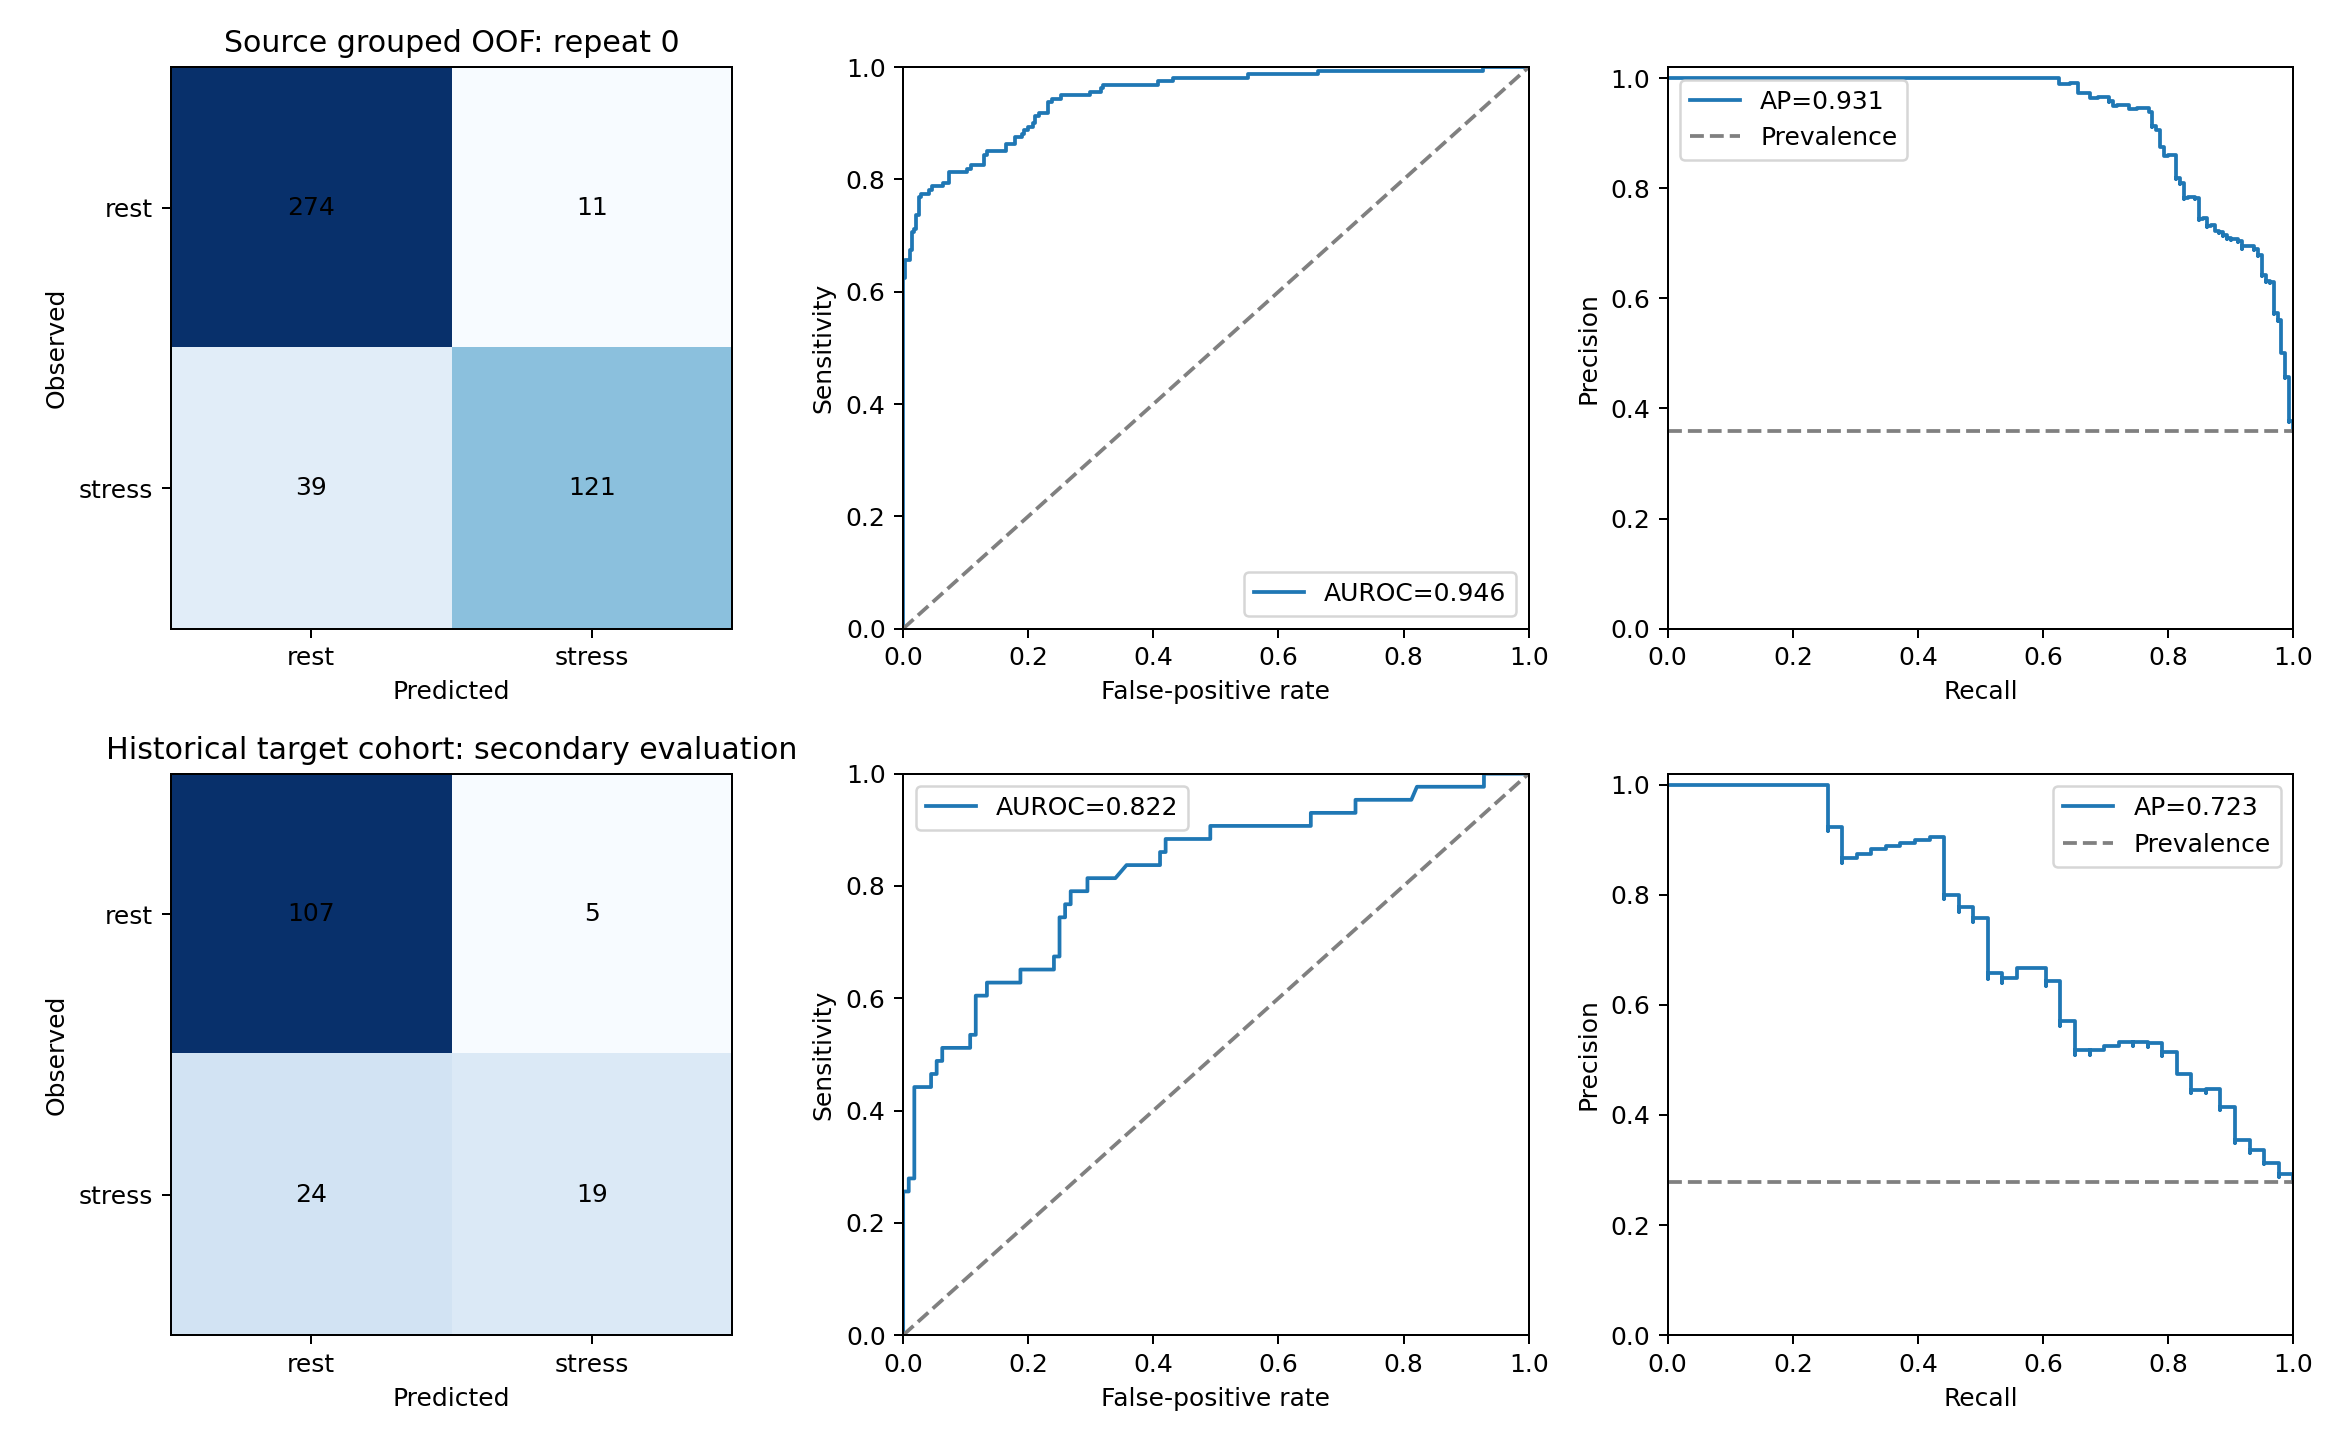

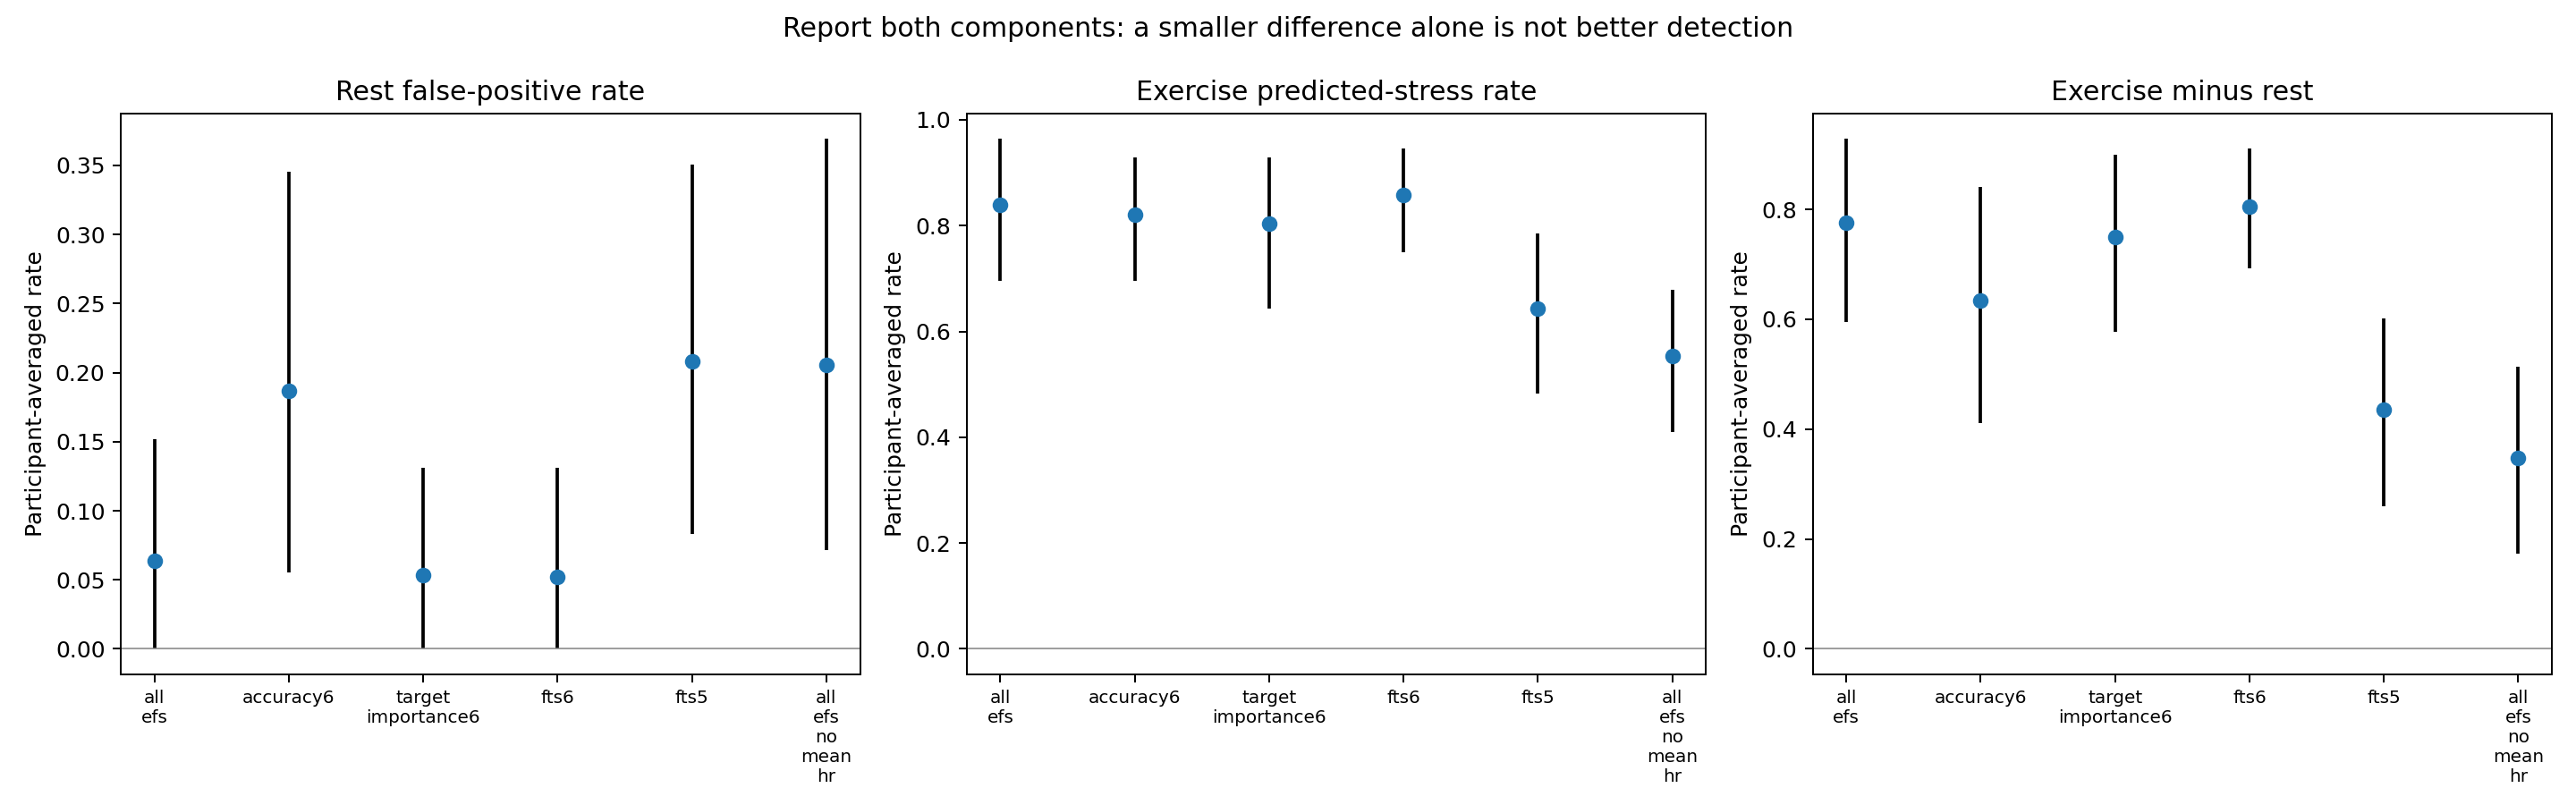

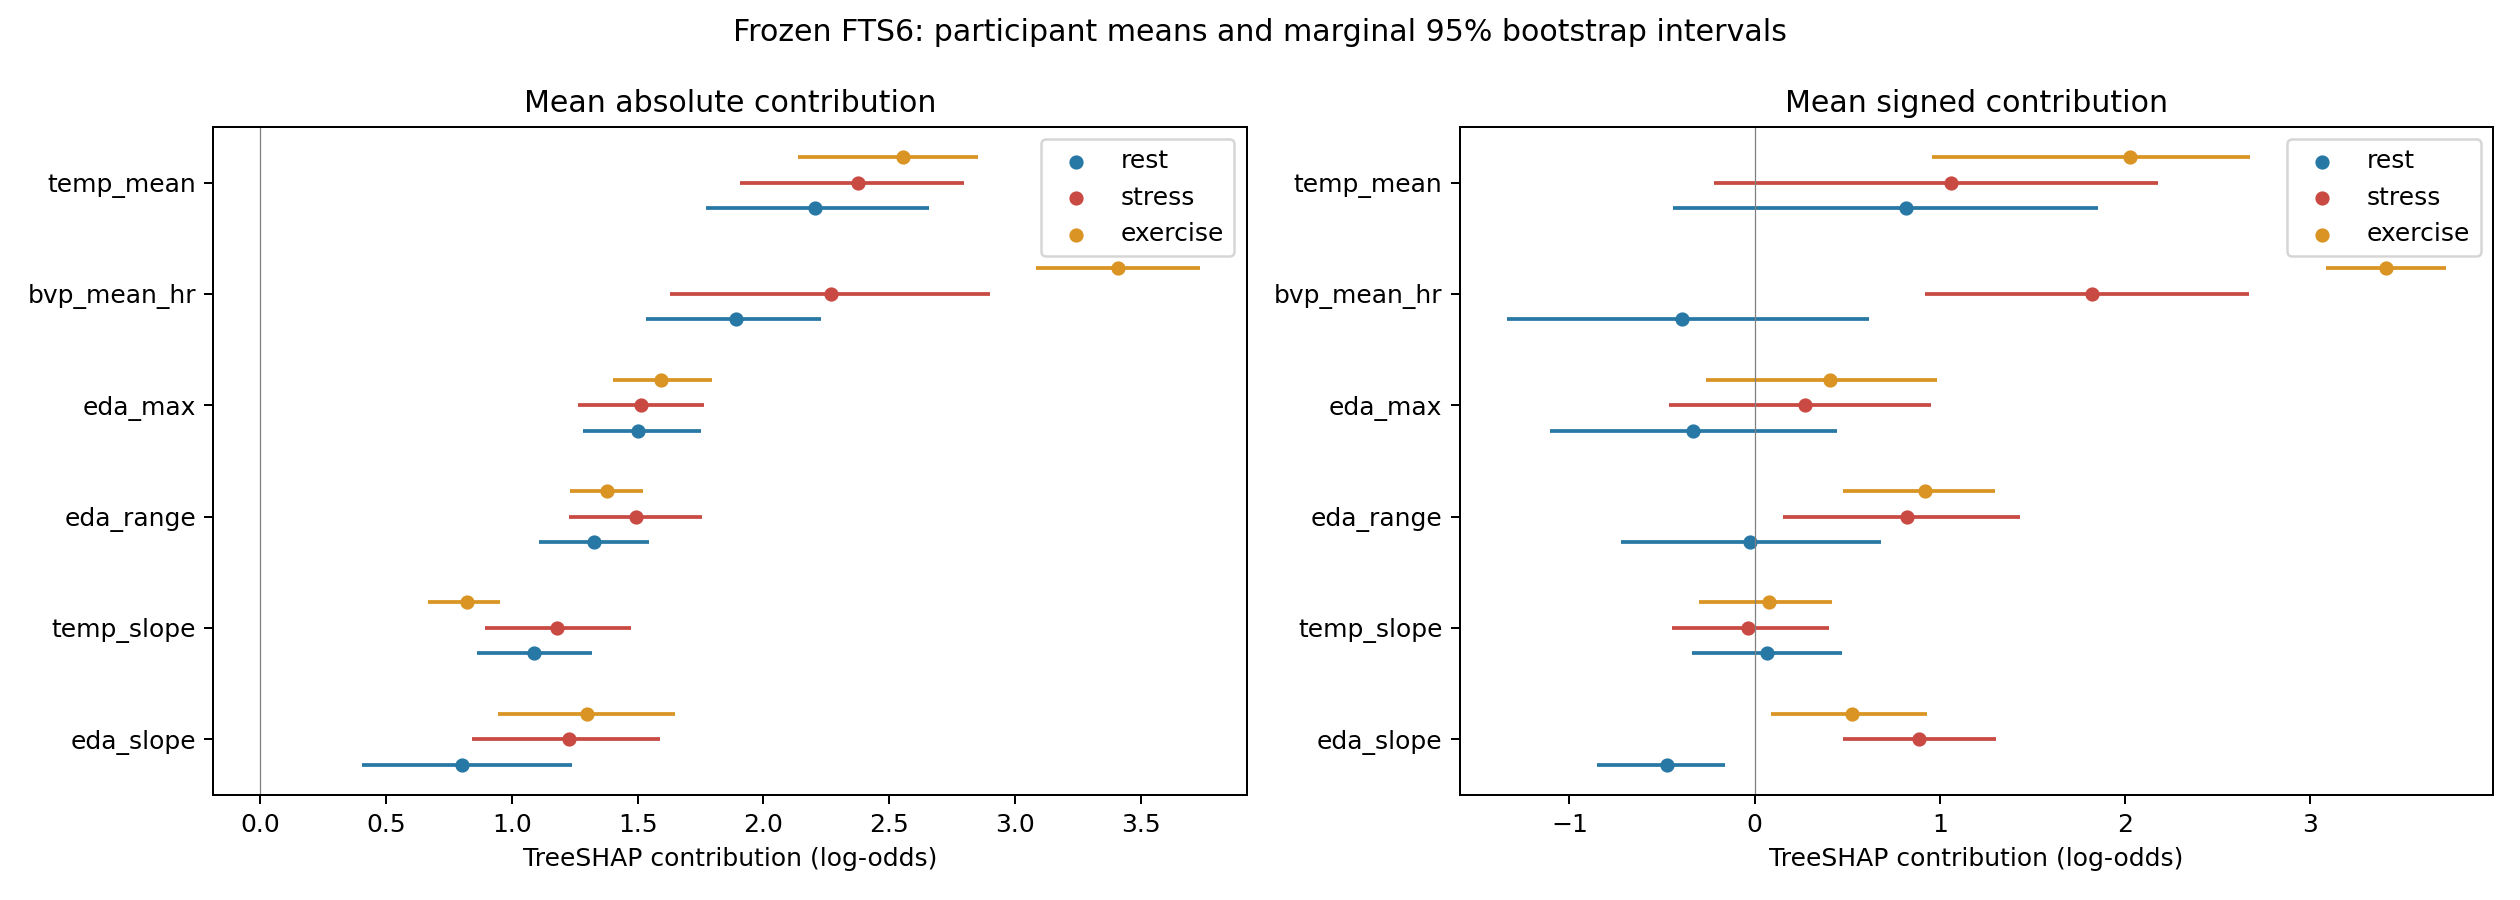

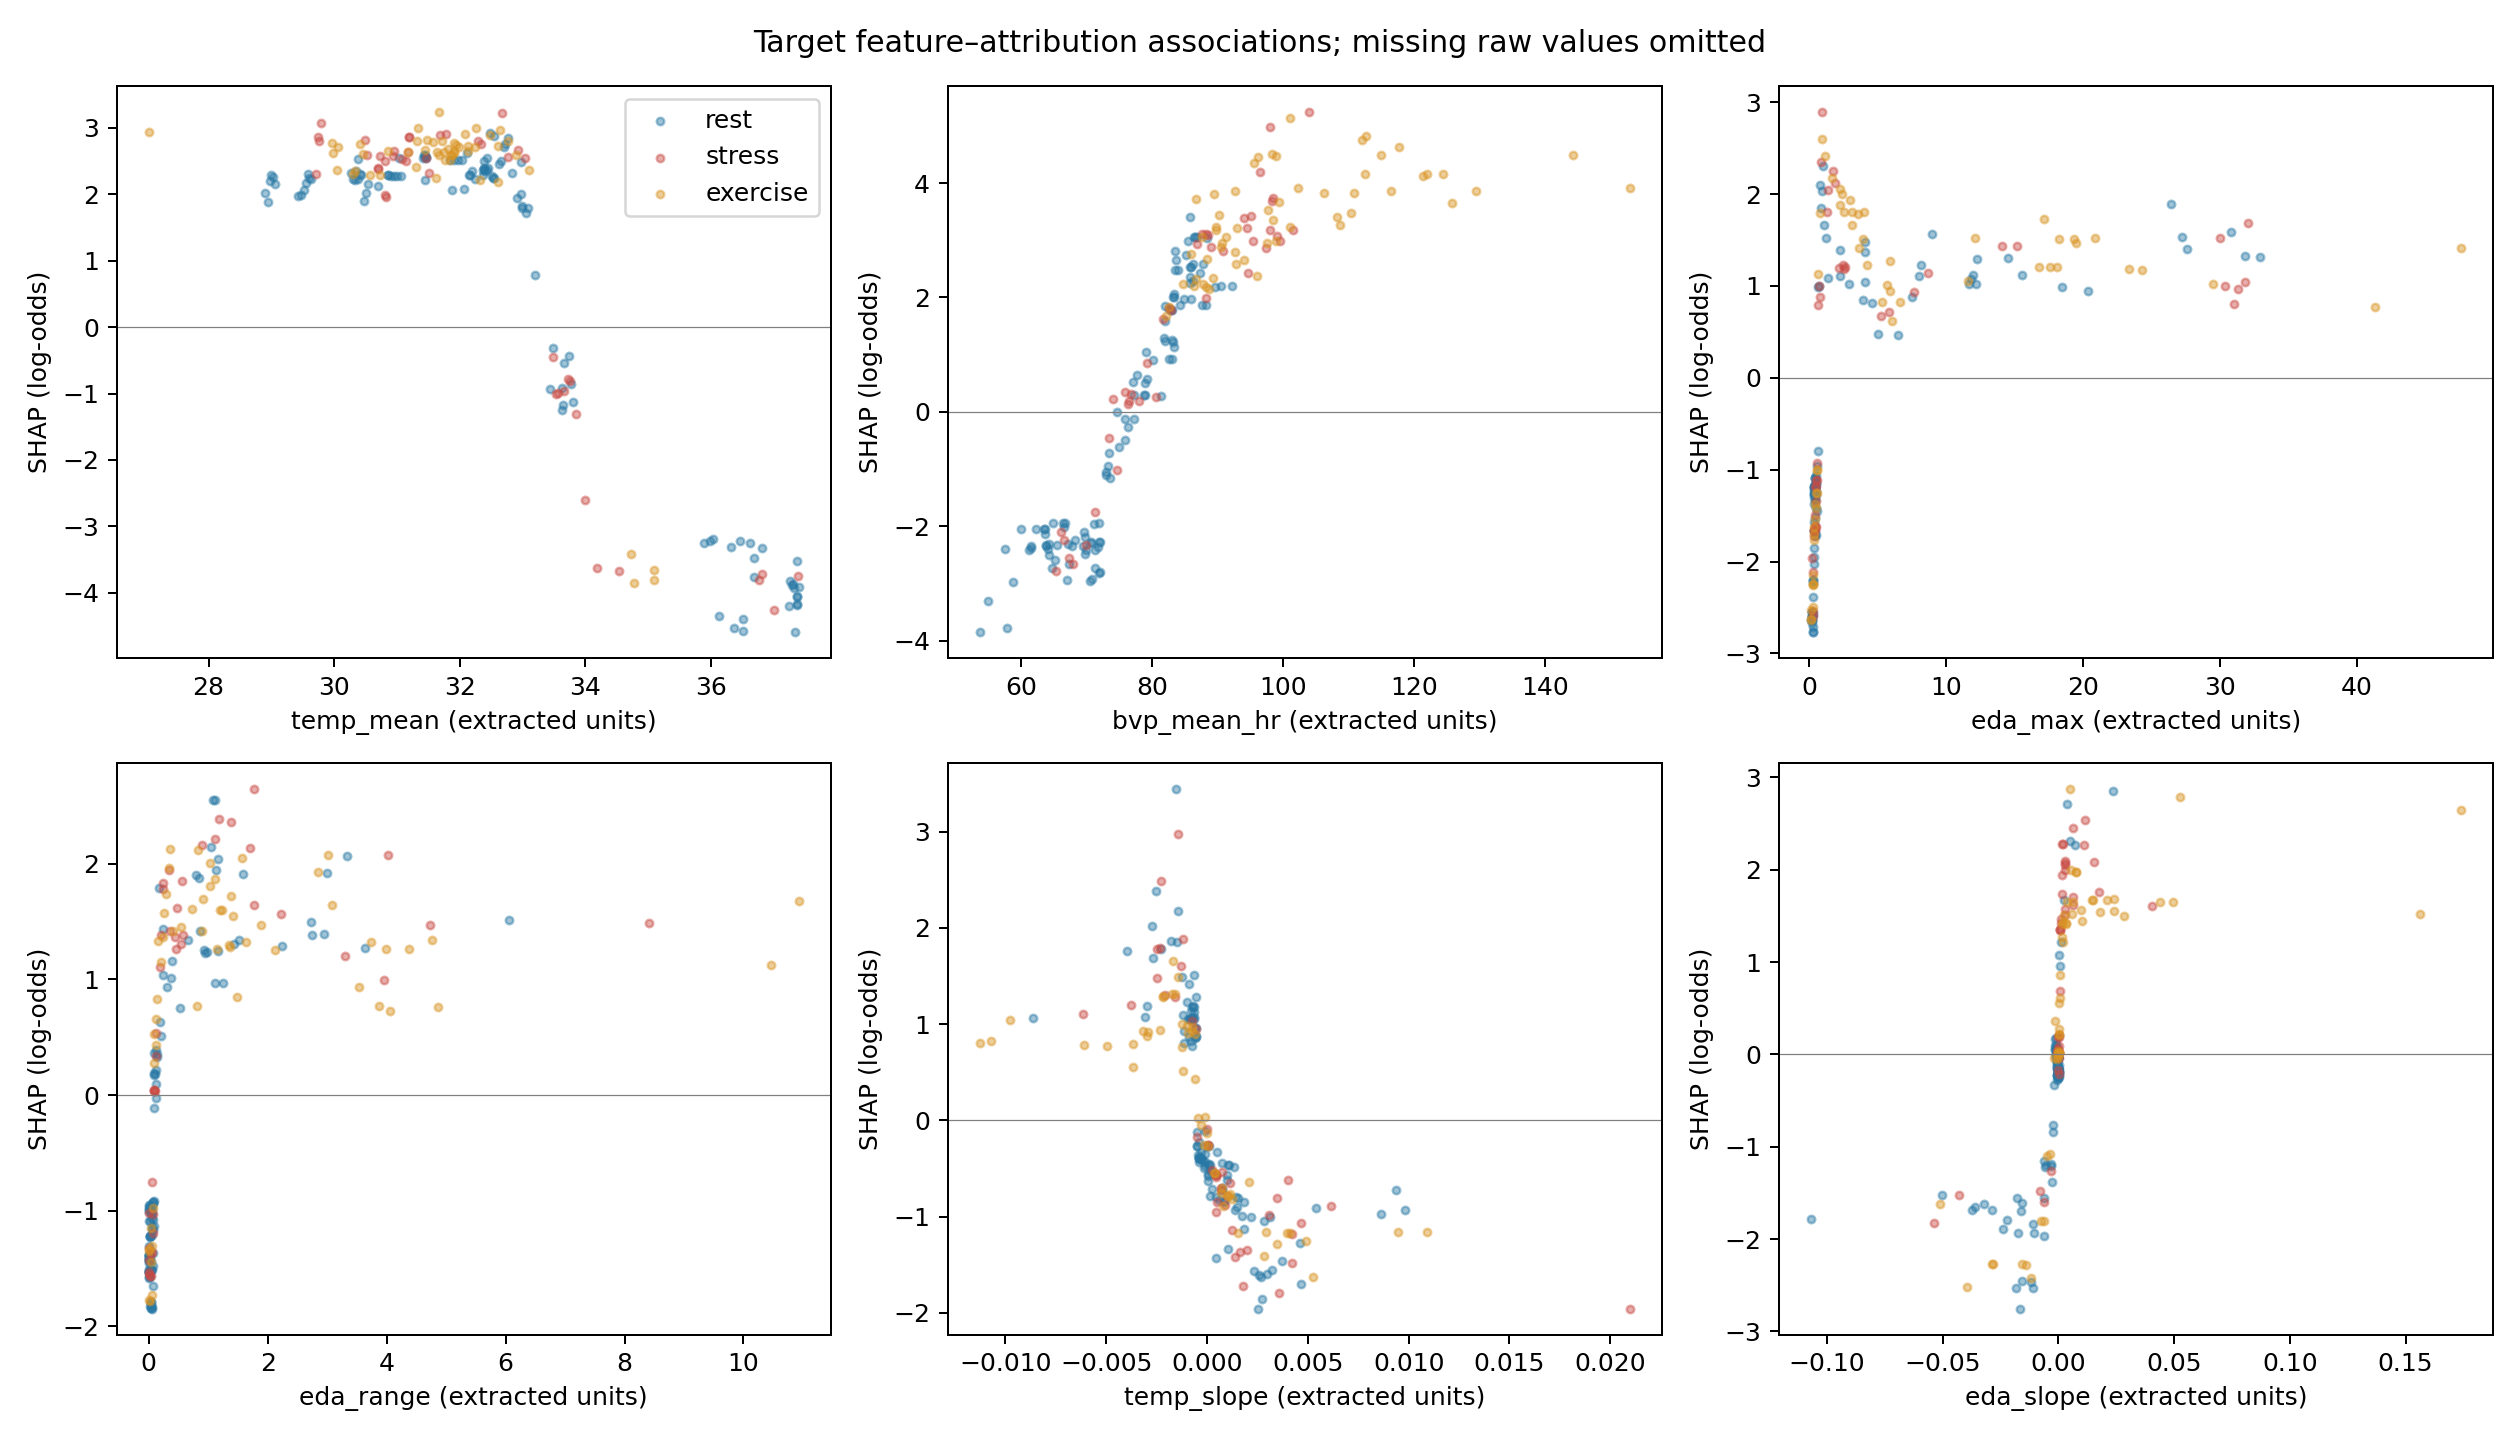

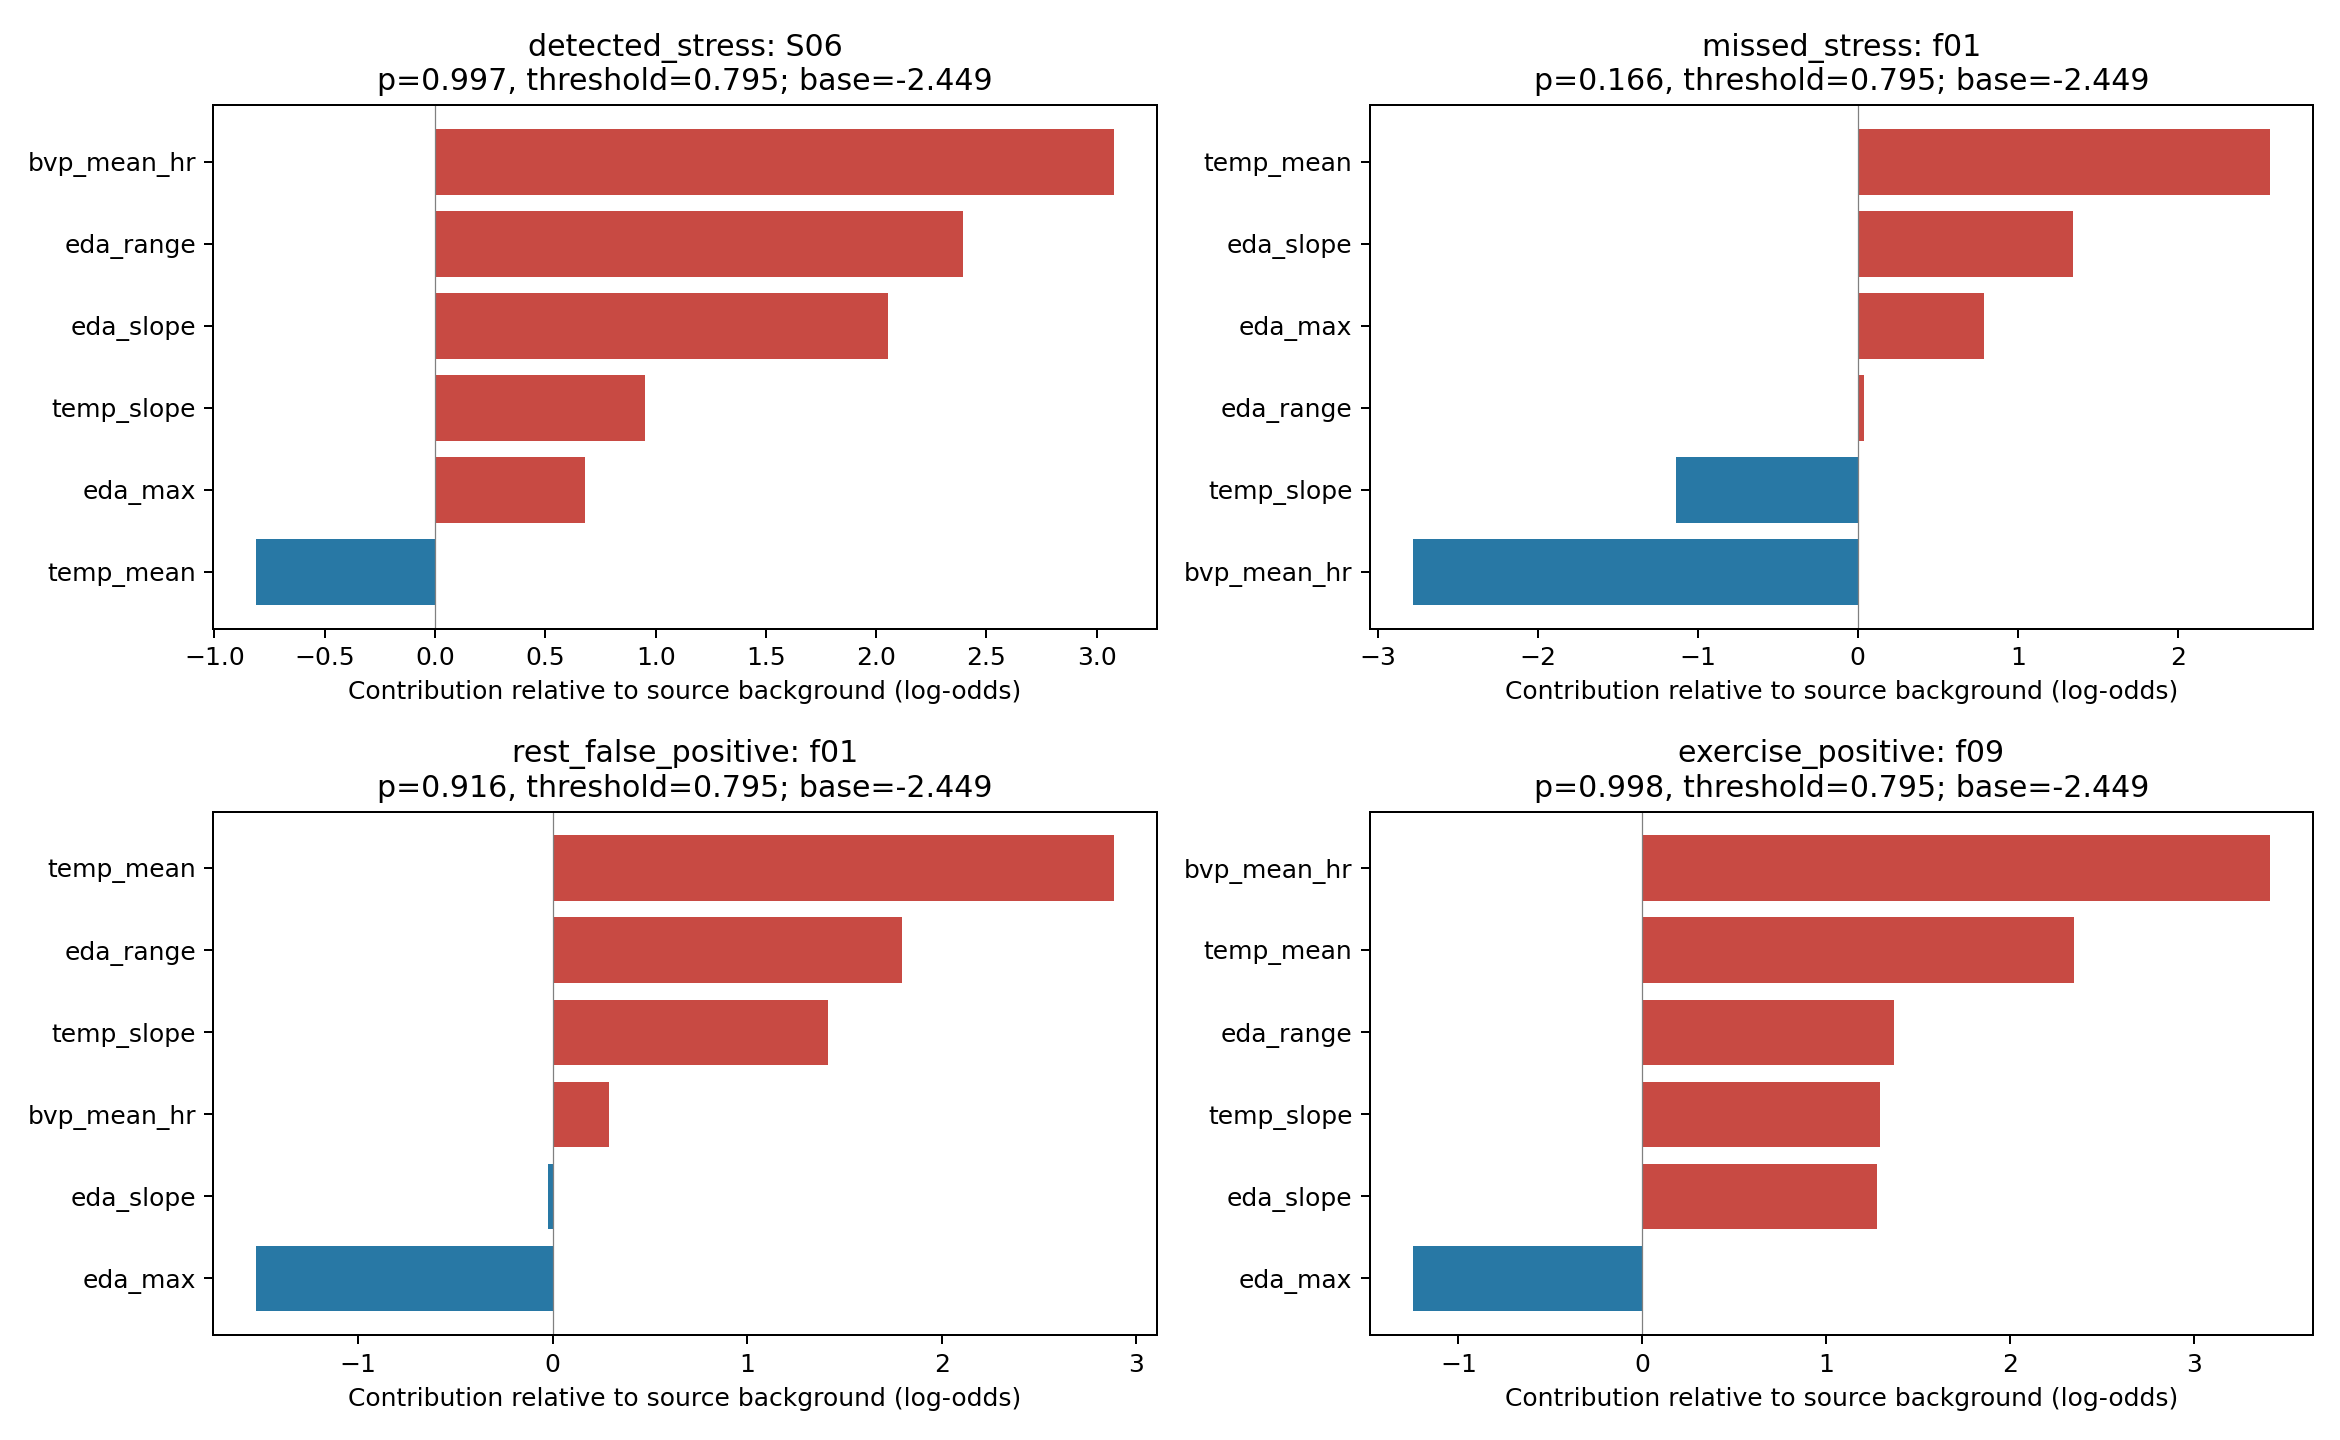

In [ ]:
for name in ['figure_diagnostics.png','figure_tradeoffs.png','figure_shap_conditions.png','figure_shap_dependence.png','figure_shap_local_examples.png']:
    path=BRANCH/'results'/name
    if not path.is_file():raise FileNotFoundError('Expected completed figure missing: '+str(path))
    display(Image(filename=str(path)))

## Cell 17 — Verify all stages and write the review archive

Re-verifies every stage hash, then writes a ZIP of all tables, figures, logs, code and settings (raw signals, feature arrays and model binaries stay in the run folder) and prints its SHA-256.

In [ ]:
execute(workflow('archive'),'archive.log',ENV)
archive=Path((RUN_ROOT.parent/(RUN_ROOT.name+'_archive_path.txt')).read_text().strip())
if not archive.is_file():raise FileNotFoundError(archive)
print('SAVED REVIEW ZIP:',archive)
print('SHA-256:',digest(archive))
print('Raw features and fitted models remain in:',RUN_ROOT)

REVIEW ZIP SAVED: /content/drive/MyDrive/FTS_publication_reanalysis/complete_runs/fts_complete_7_d27bf7a0f70a3284_c3fa1fa34874_review.zip
SHA-256: d8d9f4e1ac0493d325be7752672d06ff5e3421f4e7877410589d68e874a6561f
SAVED REVIEW ZIP: /content/drive/MyDrive/FTS_publication_reanalysis/complete_runs/fts_complete_7_d27bf7a0f70a3284_c3fa1fa34874_review.zip
SHA-256: d8d9f4e1ac0493d325be7752672d06ff5e3421f4e7877410589d68e874a6561f
Raw features and fitted models remain in: /content/drive/MyDrive/FTS_publication_reanalysis/complete_runs/fts_complete_7_d27bf7a0f70a3284


## Cell 18 — Independently recompute the reported numbers from the archive

`tools/finish_from_review_zip.py` uses only the Python standard library and reads the review archive without importing any analysis code. It recomputes confusion counts, macro-F1, sensitivity, specificity, AUROC, Brier score and the exercise/rest rates from the stored predictions and compares them with the exported tables. A pass means the files and numbers are internally consistent; it is not a statement about scientific validity.

In [ ]:
VERIFY_ROOT = RUN_ROOT.parent/(RUN_ROOT.name + '_finishing_4842c82e85e4')
VERIFY_ROOT.mkdir(parents=True, exist_ok=True)
TOOL_PATH = VERIFY_ROOT/'finish_from_review_zip.py'
immutable_bytes(TOOL_PATH, (TOOLS_DIR/'finish_from_review_zip.py').read_bytes())

REPORT_DIR = VERIFY_ROOT/'results'/digest(archive)[:16]
REPORT_DIR.mkdir(parents=True, exist_ok=True)
result = subprocess.run([sys.executable, str(TOOL_PATH), '--archive', str(archive), '--output', str(REPORT_DIR)],
                        capture_output=True, text=True)
print(result.stdout)
if result.returncode:
    print(result.stderr)
    raise RuntimeError('Reconciliation stopped. The exact error is above.')
verification = json.loads((REPORT_DIR/'VERIFICATION_REPORT.json').read_text())
print('RESULTS PARAGRAPHS:', REPORT_DIR/'RESULTS_PARAGRAPHS.md')
print('FTS5 removed feature(s):', verification['fts5_removed_features'])
print('These checks do not establish scientific validity or journal acceptance.')

{
  "synthetic_test_fixture": false,
  "status": "listed_file_and_numerical_checks_passed",
  "verifier_version": "1.0.0",
  "archive_sha256": "d8d9f4e1ac0493d325be7752672d06ff5e3421f4e7877410589d68e874a6561f",
  "target_participants": 14,
  "quality_redevelopment": true,
  "fts5_removed_features": [
    "bvp_mean_hr"
  ],
  "fts5_is_mean_hr_removal": true,
  "publication_ready_assessed": false,
  "checked": [
    "ZIP paths and hashes",
    "recorded raw audit and software status",
    "branch identity",
    "locked thresholds",
    "matching evaluation identities",
    "confusion counts, macro-F1, sensitivity, specificity, precision, accuracy, balanced accuracy, AUROC and Brier score",
    "point estimates and finite ordered CI bounds",
    "equal-participant exercise/rest rates",
    "excess decomposition",
    "SHAP export presence and recorded audit status",
    "actual feature membership"
  ],
  "not_checked": [
    "raw signal validity",
    "independent stress ground truth",
  

## Cell 19 — Supplementary check: rest recorded in the same session as exercise

A post hoc check added after the main run. The locked models are scored on the rest period at the end of each aerobic recording, so exercise and rest can be compared within one recording session. Nothing is retrained, no threshold is changed and the archived run is not modified. Because this rest period follows exercise, it may still contain recovery effects. The script is `tools/same_session_rest_check.py`.

In [ ]:
import pandas as pd

SS_DIR = WORK_ROOT/'same_session_rest_check'
SS_DIR.mkdir(parents=True, exist_ok=True)
script_path = SS_DIR/'same_session_rest_check.py'
immutable_bytes(script_path, (TOOLS_DIR/'same_session_rest_check.py').read_bytes())
execute([PY, script_path, '--run', RUN_ROOT, '--phys', PHYS_ROOT, '--out', SS_DIR],
        'same_session_rest_check.log', env=ENV)

pd.set_option('display.width', 220, 'display.max_columns', 30, 'display.max_rows', 200)
skipped = pd.read_csv(SS_DIR / 'skipped_participants.csv')
windows = pd.read_csv(SS_DIR / 'same_session_rest_windows.csv')
summary = pd.read_csv(SS_DIR / 'same_session_summary.csv')

print('Participants with same-session rest windows:')
print(windows.groupby(['partition', 'subject_id']).size().rename('windows').reset_index().to_string(index=False))
print('\nParticipants skipped (and why):')
print(skipped.to_string(index=False) if len(skipped) else 'none')
print('\nWindows with a flagged channel:', int((windows.flagged_channels.fillna('') != '').sum()), 'of', len(windows))

ev = summary[summary.partition == 'evaluation'].copy()
ev['value'] = ev.apply(lambda r: f"{r.estimate:.3f} ({r.ci_low:.3f} to {r.ci_high:.3f})", axis=1)
table = ev.pivot_table(index=['analysis', 'feature_set', 'n_participants'], columns='metric',
                       values='value', aggfunc='first')[
    ['same_session_rest', 'cross_session_rest', 'exercise', 'excess_same_session', 'excess_cross_session']]
print('\nEVALUATION COHORT - equal-participant predicted-stress rates, estimate (95% CI):')
print(table.to_string())
print('\nSaved to', SS_DIR)

S01: 2 same-session rest window(s)
S09: 1 same-session rest window(s)
S13: 2 same-session rest window(s)
S14: 2 same-session rest window(s)
S15: 2 same-session rest window(s)
/content/fts_complete_env_fc9f5ddd9345e818/lib/python3.13/site-packages/neurokit2/eda/eda_peaks.py:127: RuntimeWarning: All-NaN slice encountered
  info["SCR_Peaks"] > np.nanmin(info["SCR_Onsets"]), ~np.isnan(info["SCR_Onsets"])
S17: 1 same-session rest window(s)
f02: 2 same-session rest window(s)
f03: 2 same-session rest window(s)
f04: 1 same-session rest window(s)
f06: 1 same-session rest window(s)
f08: 2 same-session rest window(s)
S04: 2 same-session rest window(s)
S05: 1 same-session rest window(s)
S06: 1 same-session rest window(s)
S08: 1 same-session rest window(s)
S10: 2 same-session rest window(s)
S16: 1 same-session rest window(s)
S18: 2 same-session rest window(s)
f01: 2 same-session rest window(s)
f05: 1 same-session rest window(s)
f09: 1 same-session rest window(s)
f10: 1 same-session rest window(s)
f